In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize as scpo
import scipy.stats

In [2]:
files = ['sponge1.dat']
mass_error = 0.3 # g - YOU need to THINK about this!


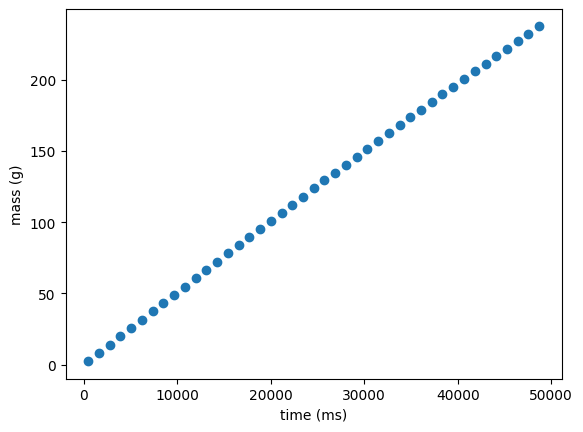

In [3]:
plt.figure()
for file in files:
    time, mass = np.loadtxt(file, unpack=True)
    time = time[:43]
    mass = mass[:43]
    plt.errorbar(time, mass, 
                 yerr=mass_error*np.ones(len(mass)),
                 marker='o', linestyle='None')
plt.xlabel('time (ms)')
plt.ylabel('mass (g)')
plt.show()


In [4]:
x_values = np.array(time)/1000
y_values = np.array(mass)
y_errors = np.array(mass_error*np.ones(len(mass)))

#x_values, y_values, y_errors = np.loadtxt(filename, unpack=True) # read columns of data from a file

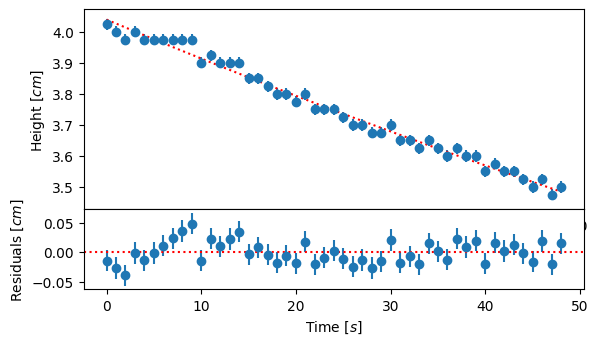

chi^2_min = 54.889073999710455
reduced chi^2 = 1.1678526382917118
P(chi^2_min, DoF) = 0.2004305715497046
optimised parameter[0] = (0.004476413386799238 +/- 7.862608756934148e-05) units
optimised parameter[1] = (1.1711485894825169 +/- 0.00534833306055241) units


In [ ]:
#### calculate dm/dt

h1 = np.array([40.25,40,39.75,40,39.75,39.75,39.75,39.75,39.75,39.75,39,39.25,39,39,39,38.5,38.5,38.25,38,38,37.75,38,37.5,37.5,37.5,37.25,37,37,36.75,36.75,37,
               36.5,36.5,36.25,36.5,36.25,36,36.25,36,36,35.5,35.75,35.5,35.5,35.25,35,35.25,34.75,35])/10
h1err = h1*0 + 0.18/10
ht = np.arange(49)

########################    

def model_functionh(x, *params):
    return (4.025 - 1.1565732008880067)*np.exp(-1*params[0]*x) + params[1]

initial_valuesh = np.array([ 0.004, 1]) # Initial guess for fit parameters

##########################################
popt, cov = scipy.optimize.curve_fit(model_functionh, # function to fit
                                     ht, # x data
                                     h1, # y data
                                     sigma=h1err, # array of error bars for the fit
                                     absolute_sigma=True, # errors bars DO represent 1 std error
                                     p0=initial_valuesh, # starting point for fit
                                     check_finite=True) # raise ValueError if NaN encountered (don't allow errors to pass)


fig1 = plt.figure(1,figsize=(5,2))
ax1 = fig1.add_axes((0,0,1,1))
ax1.errorbar(ht, 
             h1, 
             yerr=h1err, 
             marker='o', 
             linestyle='None')
#ax1.set_xlabel('Time (s)') # Axis labels
ax1.set_ylabel('Height [$cm$]')

smooth_x = np.linspace(ht[0], ht[-1], 1000) # more points, over range of data
ax1.plot(smooth_x, 
         model_functionh(smooth_x , *popt), 
         color='r', linestyle = ':')

###Residual Plotting########
resid_h = (h1 - model_functionh(ht, *popt))
ax2 = fig1.add_axes((0,-0.4,1,0.4),sharex = ax1)
ax2.errorbar(ht,resid_h,yerr=h1err,marker = 'o',linestyle = 'None')
ax2.axhline(ls=":",color = 'red')
ax2.set_xlabel('Time [$s$]') # Axis labels
ax2.set_ylabel('Residuals [$cm$]')


plt.show()
#fig1.savefig("WaterHeightPlot.png",bbox_inches='tight')

######################################################
def chi_squared(model_params, model, x_data, y_data, y_err):
    return np.sum(((y_data - model(x_data, *model_params))/y_err)**2) # Note the `*model_params' here!


chi_squared_min = chi_squared(popt, model_functionh, ht, h1, h1err)
print('chi^2_min = {}'.format(chi_squared_min))

degrees_of_freedom = ht.size - popt.size
print('reduced chi^2 = {}'.format(chi_squared_min/degrees_of_freedom))
print('P(chi^2_min, DoF) = {}'.format(scipy.stats.chi2.sf(chi_squared_min, degrees_of_freedom)))

popt_errs = np.sqrt(np.diag(cov))

for i, (val, err) in enumerate(zip(popt, popt_errs)):
    print('optimised parameter[{}] = ({} +/- {}) units'.format(i, val, err))


###############

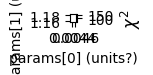

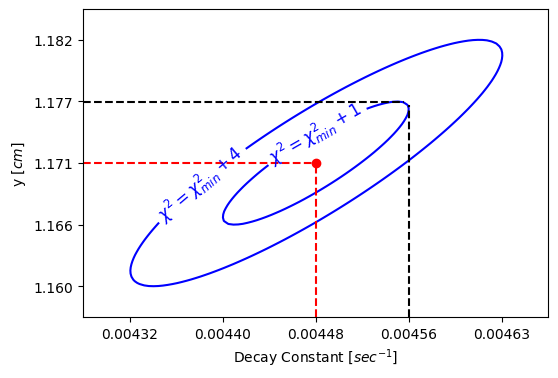

In [ ]:
alphah_p_err = 0.004476413386799238 + 7.862608756934148e-05
y_p_err = 1.1711485894825169 + 0.00534833306055241

assert(popt.size == 2) # contour plot only 'works' for 2D parameter space!

extent = 2.5 # standard errors
n_points = 100 # mesh density         

p0_range = extent * popt_errs[0]
p1_range = extent * popt_errs[1]

# Generate grid and data
p0_axis = np.linspace(popt[0]-p0_range, popt[0]+p0_range, num=n_points)
p1_axis = np.linspace(popt[1]-p1_range, popt[1]+p1_range, num=n_points)
plot_data = np.zeros((n_points, n_points))

for j, p1_val in enumerate(p1_axis): 
    for i, p0_val in enumerate(p0_axis): # Nested loops for 'clarity'...
        plot_data[j][i] = chi_squared([p0_val, p1_val], # function evaluated n_points*n_points times!
                                      model_functionh, 
                                      ht, 
                                      h1, 
                                      h1err)
        
assert(popt.size == 2) # contour plot only 'works' for 2D parameter space!

plt.figure(figsize=(0.1,0.1))
im = plt.imshow(plot_data, # grid of chi-squared values
                extent=(p0_axis[0], p0_axis[-1], # 'x' range
                        p1_axis[0], p1_axis[-1]), # 'y' range
                origin='lower', aspect='auto')

plt.xlim(popt[0]-p0_range, popt[0]+p0_range) # axis ranges
plt.ylim(popt[1]-p1_range, popt[1]+p1_range)

plt.ylabel('params[1] (units?)') # Axis labels
plt.xlabel('params[0] (units?)')

cbar=plt.colorbar(im, orientation='vertical') # Colorbar and label
cbar.set_label(r'$\chi^2$', fontsize=12)

# Add in best fit point and dashed lines to the axes
plt.plot(popt[0], popt[1], 'wo') 
plt.plot((popt[0], popt[0]), (p1_axis[0], popt[1]), # vertical line
         linestyle='--', color='w')
plt.plot((p0_axis[0], popt[0]), (popt[1], popt[1]), # horizontal line
         linestyle='--', color='w')


assert(popt.size == 2) # contour plot only 'works' for 2D parameter space!

X, Y = np.meshgrid(p0_axis, p1_axis, indexing='xy')
contour_data = plot_data - chi_squared_min

levels = [1,4] # Contour levels in delta chi-squared of 1, 4 & 9 correspond to 1, 2 & 3 standard errors
plt.figure(figsize=(6,4))

#Plot and label contours: (comment out labelling to remove text over contours)
contour_plot = plt.contour(X, Y, contour_data, levels=levels, colors='b', origin='lower')
plt.clabel(contour_plot, levels, fontsize=12, inline=1, fmt=r'$\chi^2 = \chi^2_{min}+%1.0f$') 

plt.xlabel('Decay Constant [$sec^{-1}$]') 
plt.ylabel('y [$cm$]')

import matplotlib.ticker as ticker # Allows you to modify the tick markers to 
xtick_spacing = 7.862608756934148e-05        # assess the errors from the chi-squared 
ytick_spacing = 0.00534833306055241        # contour plots - set as appropriate
ax = plt.gca()
ax.xaxis.set_major_locator(ticker.MultipleLocator(xtick_spacing,-0.0000053))
ax.xaxis.set_major_formatter('{x:.5f}') # 2 decimal places - may or may not be appropriate!

ax.yaxis.set_major_locator(ticker.MultipleLocator(ytick_spacing,-0.00013))
ax.yaxis.set_major_formatter('{x:.3f}') # 2 decimal places - may or may not be appropriate!

# Add in best fit point and dashed lines to the axes
plt.plot(popt[0], popt[1], 'ro') 
plt.plot((popt[0], popt[0]), (p1_axis[0], popt[1]), linestyle='--', color='r')
plt.plot((p0_axis[0], popt[0]), (popt[1], popt[1]), linestyle='--', color='r')
ax.axhline(y_p_err,0,0.69,ls="--",color = 'black')
ax.axvline(alphah_p_err,0,0.69,ls="--",color = 'black')
#plt.gcf().savefig("WaterHeightCountour.png",bbox_inches='tight')
plt.show()

In [68]:
m1 = 1717.980
m2 = 1761.768
m0p = (m1 - 0.997*400*1.171)
def model_function(x, *params):
    return m0p*(1-np.exp(-1*params[0]*x)) + params[1]

initial_values = np.array([0.003,0.08]) # Initial guess for fit parameters


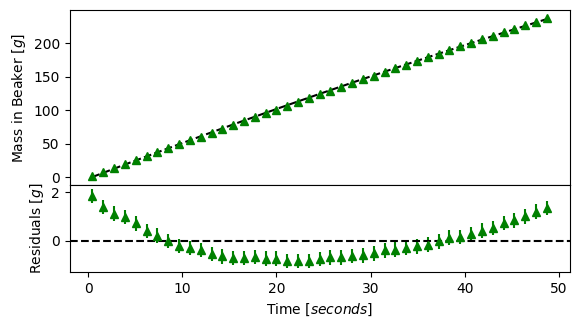

In [ ]:
popt, cov = scipy.optimize.curve_fit(model_function, # function to fit
                                     x_values, # x data
                                     y_values, # y data
                                     sigma=y_errors, # array of error bars for the fit
                                     absolute_sigma=True, # errors bars DO represent 1 std error
                                     p0=initial_values, # starting point for fit
                                     check_finite=True) # raise ValueError if NaN encountered (don't allow errors to pass)


fig2 = plt.figure(figsize=(5,1.75))
ax3 = fig2.add_axes((0,0,1,1))
ax3.errorbar(x_values,y_values, yerr=y_errors,marker='^', color = 'green',linestyle='None')


#ax3.xlabel('Time [$s$]') # Axis labels
ax3.set_ylabel('Mass in Beaker [$g$]')

smooth_x = np.linspace(x_values[0], x_values[-1], 1000) # more points, over range of data
plt.plot(smooth_x, model_function(smooth_x , *popt), color='black', linestyle='--')


resid = (y_values - model_function(x_values, *popt))
ax4 = fig2.add_axes((0,-0.5,1,0.5),sharex = ax3)
ax4.errorbar(x_values,resid,yerr=y_errors,marker = '^',color = 'green' ,linestyle = 'None')
ax4.axhline(ls="--",color = 'black')
ax4.set_xlabel('Time [$seconds$]') # Axis labels
ax4.set_ylabel('Residuals [$g$]')



plt.show()
#fig2.savefig("WaterMassPlot.png",bbox_inches='tight')

In [70]:
def chi_squared(model_params, model, x_data, y_data, y_err):
    return np.sum(((y_data - model(x_data, *model_params))/y_err)**2) # Note the `*model_params' here!


chi_squared_min = chi_squared(popt, model_function, x_values, y_values, y_errors)
print('chi^2_min = {}'.format(chi_squared_min))

degrees_of_freedom = x_values.size - popt.size
print('reduced chi^2 = {}'.format(chi_squared_min/degrees_of_freedom))
print('P(chi^2_min, DoF) = {}'.format(scipy.stats.chi2.sf(chi_squared_min, degrees_of_freedom)))

popt_errs = np.sqrt(np.diag(cov))

for i, (val, err) in enumerate(zip(popt, popt_errs)):
    print('optimised parameter[{}] = ({} +/- {}) units'.format(i, val, err))


chi^2_min = 256.56718534507627
reduced chi^2 = 6.25773622792869
P(chi^2_min, DoF) = 5.426157301870979e-33
optimised parameter[0] = (0.004340034328011998 +/- 3.178391507129944e-06) units
optimised parameter[1] = (-2.108870738983228 +/- 0.09642748639601634) units


<>:40: SyntaxWarning: invalid escape sequence '\c'
<>:40: SyntaxWarning: invalid escape sequence '\c'
C:\Users\Lucas G\AppData\Local\Temp\ipykernel_51688\1364852093.py:40: SyntaxWarning: invalid escape sequence '\c'
  cbar.set_label('$\chi^2$', fontsize=12)


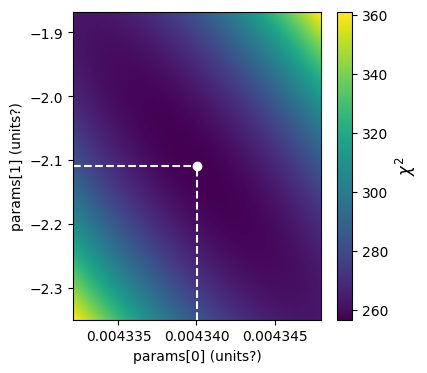

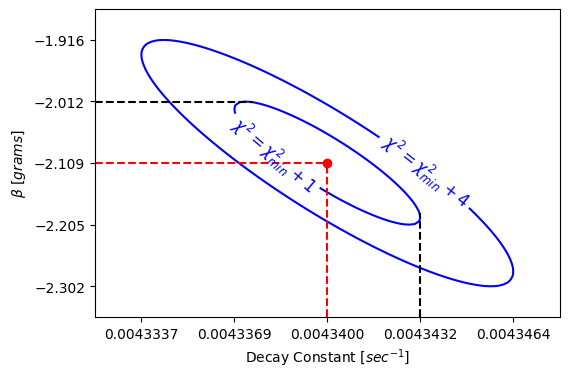

In [ ]:
alpha_p_err = 0.004340034328011998 + 3.178391507129944e-06
beta_p_err = -2.108870738983228 + 0.09642748639601634

assert(popt.size == 2) # contour plot only 'works' for 2D parameter space!

extent = 2.5 # standard errors
n_points = 100 # mesh density         

p0_range = extent * popt_errs[0]
p1_range = extent * popt_errs[1]

# Generate grid and data
p0_axis = np.linspace(popt[0]-p0_range, popt[0]+p0_range, num=n_points)
p1_axis = np.linspace(popt[1]-p1_range, popt[1]+p1_range, num=n_points)
plot_data = np.zeros((n_points, n_points))

for j, p1_val in enumerate(p1_axis): 
    for i, p0_val in enumerate(p0_axis): # Nested loops for 'clarity'...
        plot_data[j][i] = chi_squared([p0_val, p1_val], # function evaluated n_points*n_points times!
                                      model_function, 
                                      x_values, 
                                      y_values, 
                                      y_errors)
        
assert(popt.size == 2) # contour plot only 'works' for 2D parameter space!

plt.figure(figsize=(4,4))
im = plt.imshow(plot_data, # grid of chi-squared values
                extent=(p0_axis[0], p0_axis[-1], # 'x' range
                        p1_axis[0], p1_axis[-1]), # 'y' range
                origin='lower', aspect='auto')

plt.xlim(popt[0]-p0_range, popt[0]+p0_range) # axis ranges
plt.ylim(popt[1]-p1_range, popt[1]+p1_range)

plt.ylabel('params[1] (units?)') # Axis labels
plt.xlabel('params[0] (units?)')

cbar=plt.colorbar(im, orientation='vertical') # Colorbar and label
cbar.set_label('$\chi^2$', fontsize=12)

# Add in best fit point and dashed lines to the axes
plt.plot(popt[0], popt[1], 'wo') 
plt.plot((popt[0], popt[0]), (p1_axis[0], popt[1]), # vertical line
         linestyle='--', color='w')
plt.plot((p0_axis[0], popt[0]), (popt[1], popt[1]), # horizontal line
         linestyle='--', color='w')


assert(popt.size == 2) # contour plot only 'works' for 2D parameter space!

X, Y = np.meshgrid(p0_axis, p1_axis, indexing='xy')
contour_data = plot_data - chi_squared_min

levels = [1,4] # Contour levels in delta chi-squared of 1, 4 & 9 correspond to 1, 2 & 3 standard errors
plt.figure(figsize=(6,4))

#Plot and label contours: (comment out labelling to remove text over contours)
contour_plot = plt.contour(X, Y, contour_data, levels=levels, colors='b', origin='lower')
plt.clabel(contour_plot, levels, fontsize=12, inline=1, fmt=r'$\chi^2 = \chi^2_{min}+%1.0f$') 

plt.xlabel('Decay Constant [$sec^{-1}$]') 
plt.ylabel(r'$\beta$ [$grams$]')

import matplotlib.ticker as ticker # Allows you to modify the tick markers to 
xtick_spacing = 3.178391507129944e-06         # assess the errors from the chi-squared 
ytick_spacing = 0.09642748639601634         # contour plots - set as appropriate
ax = plt.gca()
ax.xaxis.set_major_locator(ticker.MultipleLocator(xtick_spacing,0.000001534))
ax.xaxis.set_major_formatter('{x:.7f}') # 2 decimal places - may or may not be appropriate!

ax.yaxis.set_major_locator(ticker.MultipleLocator(ytick_spacing,0.0127))
ax.yaxis.set_major_formatter('{x:.3f}') # 2 decimal places - may or may not be appropriate!

# Add in best fit point and dashed lines to the axes
plt.plot(popt[0], popt[1], 'ro') 
plt.plot((popt[0], popt[0]), (p1_axis[0], popt[1]), linestyle='--', color='r')
plt.plot((p0_axis[0], popt[0]), (popt[1], popt[1]), linestyle='--', color='r')
ax.axhline(beta_p_err,0,0.34,ls="--",color = 'black')
ax.axvline(alpha_p_err,0,2.70/8,ls="--",color = 'black')
#plt.gcf().savefig("WaterMassCountour.png",bbox_inches='tight')
plt.show()

In [12]:
import numpy as np
import math 
import matplotlib.pyplot as plt
import pandas as pd
import scipy.optimize as scpo


class UDS:
    def __init__(self,data_matrix):
        self.data = data_matrix

    @classmethod
    #The bellow function will save the data as a UDS object. The data will be in the form [[row1col1, row1col2,row1col3,...],[row2col1, row2col2, row2col3,...],...]
    def data_excel(cls, file, rows, colums, sheet_nm = "Sheet1"): #"file name",[1,3],"A:B"
        pd_file = pd.read_excel(file + ".xlsx",sheet_name=sheet_nm, usecols= colums)
        just_data = pd_file.iloc[rows[0]-2:rows[1]-1]
        fin_data = just_data.values.tolist()
        return cls(fin_data)
    
#Utility functions
    @staticmethod
    def flatten(matrix):
        flat_list = []
        for row in matrix:
            flat_list.extend(row)
        return flat_list
    @staticmethod
    def sci_e_equal(num1,num2,round = 10):
        e_1 = 10**(int(math.log10(num1))-1)
        if e_1 < 0.0001:
            e_1_s = "{0}".format(e_1)
            e_1_s = e_1_s[1:]
            prop_num2 = "{0}".format((num2 * e_1**-1))
            return prop_num2 + e_1_s
        else:
            e_2 = -1*(int(math.log10(num2))-round) 
            e_2_f = ':.{0}'.format(e_2)
            e_2_f = '{' + e_2_f + 'f}'
            return e_2_f.format(num2)

    def getData(self):  #Return data matrix
        return self.data

#Bellow are methods to calculate and display the error of a value using the functional aproach

    def functional_err(self, f, return_comp = False):
        comp_err = []
        orig_val = []
        for i in self.data:
            orig_val += [i[0]]
        fin_val = f(*orig_val)

        for i in range(len(self.data)):
            cur_val = orig_val.copy()
            cur_val[i] += self.data[i][1]
            comp_err += [abs(f(*cur_val) - fin_val)]

        fin_err = 0
        for i in comp_err:
            fin_err += i**2
        fin_err = (fin_err)**0.5
        
        if return_comp:
            return [[fin_val, fin_err], comp_err]
        return [fin_val, fin_err]
    
    def display_func_err(self, f, show_comp = False, **kwargs):
        fig = plt.figure(1) 
        fig.add_axes((0,0,0.75,0.10))
        ax = fig.gca()

        fx_name = "Z"
        fx_units = "n/a"
        comp_tbl_row = []  #The labels for the component table rows
        alphabet = ["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O","P","Q","R","S","T","U","V","W","x","Y","Z"]

        if 'f_name' in kwargs:
            fx_name = kwargs['f_name']
        if 'f_units' in kwargs:
            fx_units = kwargs['f_units']

        if show_comp:
            all_data = self.functional_err(f,return_comp= True)
            val_fin = all_data[0][0]
            err_fin = all_data[0][1]
            comp_err = all_data[1].copy()
            tbl_comp_err = []  #Holds the actual values to display in the component err table
            var_names = alphabet[:len(self.data)]
            if 'var_names' in kwargs:
                var_names = kwargs['var_names']
            for i in range(len(comp_err)):
                tbl_comp_err += [[comp_err[i]]]
                comp_tbl_row += ["$\\alpha_{0}^{{{1}}}$".format(fx_name,var_names[i])]

        else:
            all_data = self.functional_err(f,return_comp= False)
            val_fin = all_data[0]
            err_fin = all_data[1]


        # hide axes
        ax.axis('off')
        ax.axis('tight')
        axtl = r"{0}\ and\ its\ Error".format(fx_name)
        axtl = "$\\mathbfit{" + axtl + "}$"
        ax.set_title(axtl)
        fx_tbl_contents = [[val_fin,UDS.sci_e_equal(val_fin,err_fin)]]
        fx_tbl_headers = ["${0}$ (${1}$)".format(fx_name,fx_units), "$\\alpha_{0}$ (${1}$)".format(fx_name,fx_units)]

        fx_tbl = ax.table(cellText=fx_tbl_contents,cellLoc="center",colWidths= [0.5,0.5],colLabels=fx_tbl_headers, loc='center') #Table creation
        #setting the height of each cell
        for c in fx_tbl.get_celld().values():
            c.set_height(0.5)


        #### Code for error component tabel
        if show_comp:
            comp_tbl_headers = ["Component of total error (${0}$)".format(fx_units)]
            axis_height = 0.0578*len(comp_err) + 0.1424 #formula to calculate where to begin and the height of the axis based on the amount of component error

            fig.add_axes((0,-1*axis_height,0.75,axis_height))
            ax = fig.gca()
            ax.axis('off')
            ax.axis('tight')


            comp_tbl = ax.table(cellText=tbl_comp_err,cellLoc="center",colWidths=[0.5],colLabels=comp_tbl_headers,rowLabels=comp_tbl_row, loc='center')

            cell_height = 1/(2+len(comp_err))

            for c in comp_tbl.get_celld().values():
                c.set_height(cell_height)
        plt.show()


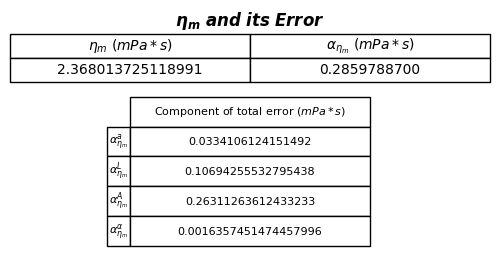

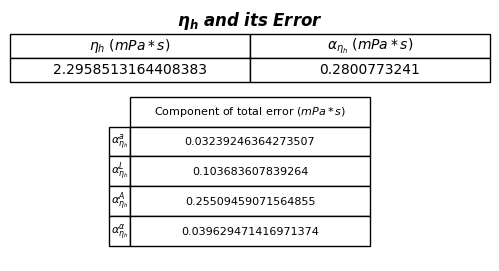

In [13]:
def n(a,L,A,alpha):
    return np.pi*(997 * 10**3)*9.81*(a)**4/(8*L*A*alpha)
a = [1.995*10**-3,7*10**-6]
L = [0.148,0.007]
A = [0.04,0.005]

alpha1 = [4.340*10**-3,0.003*10**-3]
data1 = UDS([a,L,A,alpha1])
data1.display_func_err(n,show_comp = True,f_name = r"{\eta_{m}}",f_units = "mPa*s",var_names = ["a","L","A",r"{\alpha}"])

#alpha2 = [3.0662*10**-3,8*10**-7]
#data1 = UDS([a,L,A,alpha2])
#data1.display_func_err(n,show_comp = True,f_name = r"{\eta_m1}",f_units = "mPa*s",var_names = ["a","L","A",r"{\alpha}"])

alphah = [0.004476413386799238,7.862608756934148e-05]
datah = UDS([a,L,A,alphah])
datah.display_func_err(n,show_comp = True,f_name = r"{\eta_h}",f_units = "mPa*s",var_names = ["a","L","A",r"{\alpha}"])